# AIDA 2154 Final Project – 05 Robustness of the Frozen Baseline

**Data version 2** (`shared/synthetic-data/kit-cards/`), using the method frozen in notebooks 02–04: notebook 02's segmentation, notebook 03's colour-and-shape classifier, and the card decision rule. Notebook 04 found that the network did not meet the prespecified criteria for replacing the baseline on validation, so the baseline is the method tested here.

**Question:** How do the frozen baseline's missing-item flags hold up when the kit items are drawn in unfamiliar designs, or when the card images are of poorer quality?

**Robustness cards (paired design).** The kits of the 120 validation cards (expected, omitted and unknown items, and background objects) are drawn again with the data generator's own drawing and degradation functions, imported read-only and unchanged, with a new seed (2029). Each card is drawn three times, in three **arms**, with the same layout:

- **Control:** familiar item styles (a and b) and image settings drawn from the generator's usual ranges.
- **Reserved style:** identical to the control, except that every kit item is drawn in style **c**, which the generator held back from all cards for a robustness test. Style c changes each item's colour, shape and detail together, so this arm measures the effect of switching to these designs on these cards; it cannot show which visual change matters.
- **Heavier degradation:** identical to the control, except for one fixed image-quality condition beyond the development ranges: blur radius 1.75 on every card (development: 0.3–1.0 on about 40% of cards), noise strength 10 (development: 0–6, using the same noise pattern as the control, scaled) and JPEG quality 40 (development: 60–92). Blur, noise and compression change together, so any drop is their combined effect.

The main comparisons are **control against reserved style** and **control against heavier degradation**. These are fresh renderings of the validation kits, so they test visual robustness over the same kit configurations; the original validation results are shown for context only.

**Fixed before any robustness result is seen** (`method_frozen.json`, protected): the method (segmentation settings, classifier file and decision rule, by fingerprint), the three arms and their settings, the seed, and the measures. The measures are those of notebook 03: missing-item recall (main), missing-item precision, false missing-item flags, unexpected detections and completely correct cards, plus results by item and contrast band. **Recognition is reported over every drawn item**, including items that segmentation missed or merged, alongside segmentation outcomes and region classification, so good classification of the regions that were found cannot hide items that were lost.

**What the results can and cannot show.** Nothing here changes the method: tuning on these cards would spoil the test. A drop on either arm would mean that performance under those conditions needs further evaluation before use, and that any adaptation should be assessed on a separate evaluation set; it could point to segmentation, colour features or the decision rule. Neither arm establishes performance on real photographs or scans. No test image is opened; the test set stays untouched until the single test evaluation.

In [1]:
import hashlib
import importlib.util
import io
import json
import platform
from pathlib import Path

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
import sklearn
from IPython.display import display
from PIL import Image

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
KIT = SD / "kit-cards"
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")
ITEMS = ["access_badge", "safety_vest", "hard_hat", "laptop", "phone"]
NOT_KIT = "not_kit_item"
CLASSES = ITEMS + [NOT_KIT]
ROBUSTNESS_SEED = 2029
ARMS = ["control", "reserved_style", "heavier_degradation"]
STRESS = {"blur_radius": 1.75, "noise_sigma": 10.0, "jpeg_quality": 40}       # one fixed condition, every card

sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
manifest = pd.read_csv(KIT / "manifest.csv", keep_default_na=False, na_values=[""])
objects = pd.read_csv(KIT / "icon_instances.csv", keep_default_na=False, na_values=[""])
settings = json.loads((OUTPUT_DIR / "segmentation_settings.json").read_text())          # notebook 02
baseline_settings = json.loads((OUTPUT_DIR / "classifier_settings.json").read_text())    # notebook 03
regions_saved = pd.read_csv(OUTPUT_DIR / "regions_dev.csv", keep_default_na=False, na_values=[""])
objects_saved = pd.read_csv(OUTPUT_DIR / "object_outcomes_dev.csv", keep_default_na=False, na_values=[""])
predictions_saved = pd.read_csv(OUTPUT_DIR / "region_predictions_dev.csv", keep_default_na=False, na_values=[""])
choice = pd.read_csv(OUTPUT_DIR / "tl_decision_rule_result.csv", index_col=0, dtype=str, keep_default_na=False)  # notebook 04

# The method going forward is the baseline, as recorded in notebook 04
assert choice.loc["Method that goes forward", "baseline"] == "baseline", "Notebook 04 did not choose the baseline"
MODEL_PATH = OUTPUT_DIR / baseline_settings["model_file"]
assert sha(MODEL_PATH) == baseline_settings["model_sha256"], "The baseline model file differs from notebook 03's"
assert sha(OUTPUT_DIR / "segmentation_settings.json") == baseline_settings["segmentation_settings_sha256"]
assert sha(OUTPUT_DIR / "regions_dev.csv") == baseline_settings["regions_dev_sha256"]
assert cv2.__version__ == settings["package_versions"]["opencv"] and np.__version__ == settings["package_versions"]["numpy"], \
    "The segmentation must run with the package versions it was frozen with"
model = joblib.load(MODEL_PATH)
FEATURES = baseline_settings["features"]
assert list(model.classes_) == sorted(CLASSES) and len(FEATURES) == 18

# The data generator, imported read-only so its drawing and degradation functions are used unchanged
GENERATOR_PATH = KIT / "generate_kit_cards.py"
spec = importlib.util.spec_from_file_location("kit_generator", GENERATOR_PATH)
gen = importlib.util.module_from_spec(spec)
spec.loader.exec_module(gen)
assert gen.RESERVED_STYLE == "c" and gen.DEVELOPMENT_STYLES == ["a", "b"]
assert not (objects["style"] == gen.RESERVED_STYLE).any(), "Style c must not appear on any existing card"

val_cards = manifest[manifest["split"] == "validation"].reset_index(drop=True)
val_objects = objects[objects["split"] == "validation"].reset_index(drop=True)

# The frozen method and robustness design, written before any robustness card is drawn; protected against change
frozen = {
    "data_version": DATA_VERSION,
    "method": "notebook 02 segmentation + notebook 03 baseline classifier + notebook 03 card decision rule",
    "segmentation_settings_sha256": sha(OUTPUT_DIR / "segmentation_settings.json"),
    "classifier_settings_sha256": sha(OUTPUT_DIR / "classifier_settings.json"),
    "model_file": MODEL_PATH.name, "model_sha256": baseline_settings["model_sha256"],
    "decision_rule": "an item is detected if any region on the card is classified as that item; outcomes as in notebook 03 section E",
    "method_choice_file_sha256": sha(OUTPUT_DIR / "tl_decision_rule_result.csv"),
    "robustness_design": {
        "cards": "kits of the 120 validation cards, drawn again; no test card used",
        "kit_sources": {"manifest.csv_sha256": sha(KIT / "manifest.csv"), "icon_instances.csv_sha256": sha(KIT / "icon_instances.csv")},
        "seed": ROBUSTNESS_SEED, "arms": ARMS,
        "control": "development styles a/b; image settings from the generator's ranges",
        "reserved_style": "as control, every kit item drawn in style c",
        "heavier_degradation": {"as control, except": STRESS, "noise": "same noise pattern as the control, scaled"},
        "pairing_rules": [
            "each card's layout (object order, positions, sizes, contrast, rotation, paper tint) is drawn once and shared by all arms",
            "control and heavier-degradation arms use the same styles a/b; the reserved-style arm changes only the kit items' style to c",
            "objects are placed using the box that encloses the object's drawings in every arm at the shared position and rotation",
            "the generator's 14-pixel gap between objects and from the card edges is checked separately in every arm",
            "each card's image settings and noise pattern are drawn once; control and reserved-style arms use them unchanged",
            "the heavier-degradation arm replaces blur, noise strength and JPEG quality with the fixed values and scales the shared noise pattern",
        ],
        "generator_file_sha256": sha(GENERATOR_PATH),
    },
    "measures": ["missing-item recall (main)", "missing-item precision", "false missing-item flags", "unexpected detections",
                 "completely correct cards", "by item", "by contrast band", "recognition over all drawn items",
                 "segmentation outcomes", "region classification"],
    "package_versions": {"python": platform.python_version(), "opencv": cv2.__version__, "numpy": np.__version__,
                         "pandas": pd.__version__, "scikit-learn": sklearn.__version__, "pillow": PIL.__version__},
}
FROZEN_PATH = OUTPUT_DIR / "method_frozen.json"
if FROZEN_PATH.exists():
    assert json.loads(FROZEN_PATH.read_text()) == frozen, "method_frozen.json differs from this run; the method is frozen"
    frozen_status = "matches the saved file"
else:
    FROZEN_PATH.write_text(json.dumps(frozen, indent=2) + "\n")
    frozen_status = "written"
print(f"Data version {DATA_VERSION}; method going forward: baseline (notebook 04); model and settings fingerprints checked")
print(f"Validation kits to redraw: {len(val_cards)} cards, {int((val_objects['role'] == 'kit_item').sum())} kit items, "
      f"{int((val_objects['role'] == 'background_object').sum())} background objects")
print(f"Frozen method and robustness design ({FROZEN_PATH.name}): {frozen_status}")
print("Versions:", frozen["package_versions"])

Data version 2; method going forward: baseline (notebook 04); model and settings fingerprints checked
Validation kits to redraw: 120 cards, 238 kit items, 82 background objects
Frozen method and robustness design (method_frozen.json): matches the saved file
Versions: {'python': '3.14.7', 'opencv': '4.14.0', 'numpy': '2.5.3', 'pandas': '3.0.6', 'scikit-learn': '1.9.1', 'pillow': '12.3.0'}


## A. The same pipeline, shown to be unchanged

The frozen pipeline is copied unchanged from earlier notebooks:

- notebook 02's segmentation (median filter, masked local background, grayscale difference, opening, closing, connected regions);
- notebook 02's matching of regions to drawn objects (missed, merged, split, or one region with a good or poor fit);
- notebook 02's region label groups and notebook 03's reference labels;
- notebook 03's 18 colour and shape features and saved classifier;
- notebook 03's card decision rule and summary, as copied in notebook 04.

The only change is that segmentation takes an image already in memory rather than a file name, so the robustness cards do not need to be saved; for the saved cards, the image is read from its file exactly as before.

Before any robustness card is drawn, the copied pipeline is run on the 120 saved validation cards and must reproduce notebook 02's regions and object outcomes, notebook 03's region predictions, and notebook 03's card decisions and summary exactly, or the notebook stops.

In [2]:
rows_a, rows_b = settings["content_area"]["rows"]           # inclusive bounds
cols_a, cols_b = settings["content_area"]["columns"]
CONTENT = (slice(rows_a, rows_b + 1), slice(cols_a, cols_b + 1))
chosen = settings["chosen"]
mb = settings["masked_background"]
GRAY_WEIGHTS = np.array([0.114, 0.587, 0.299], dtype=np.float32)   # OpenCV loads images as blue-green-red
OPEN = int(settings["opening"].split(" x ")[0])
IOU_GOOD = settings["iou_good_fit"]


def segment(image):
    # Notebook 02's frozen pipeline on a blue-green-red image; returns the content, paper estimate, labels, kept components, boxes
    content = cv2.medianBlur(image, settings["median_filter"])[CONTENT].astype(np.float32)
    sigma = settings["background_sigma"]
    gaussian = cv2.GaussianBlur(content, (0, 0), sigma)
    prelim = np.linalg.norm(content - gaussian, axis=2) > mb["preliminary_colour_threshold"]
    d = int(mb["preliminary_mask_dilation"].split(" x ")[0])
    prelim = cv2.dilate(prelim.astype(np.uint8), np.ones((d, d), np.uint8)).astype(bool)
    remaining = (~prelim).astype(np.float32)
    weight = cv2.GaussianBlur(remaining, (0, 0), sigma)
    paper = cv2.GaussianBlur(content * remaining[..., None], (0, 0), sigma) / np.maximum(weight, mb["minimum_background_weight"])[..., None]
    paper = np.where(weight[..., None] > mb["minimum_background_weight"], paper, gaussian)
    diff = np.abs((content - paper) @ GRAY_WEIGHTS)
    mask = (diff > chosen["threshold"]).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((OPEN, OPEN), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (chosen["close"],) * 2))
    _, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=settings["connectivity"])
    keep = [k for k in range(1, len(stats)) if stats[k][4] >= settings["min_region_pixels"]]
    boxes = [(int(stats[k][0]) + CONTENT[1].start, int(stats[k][1]) + CONTENT[0].start,
              int(stats[k][0] + stats[k][2]) + CONTENT[1].start, int(stats[k][1] + stats[k][3]) + CONTENT[0].start) for k in keep]
    return content, paper, labels, keep, boxes


def iou(r, o):
    inter = max(0, min(r[2], o[2]) - max(r[0], o[0])) * max(0, min(r[3], o[3]) - max(r[1], o[1]))
    return inter / ((r[2] - r[0]) * (r[3] - r[1]) + (o[2] - o[0]) * (o[3] - o[1]) - inter)


def overlaps(r, o):
    return r[0] < o[2] and r[2] > o[0] and r[1] < o[3] and r[3] > o[1]


def match_card(regions, card_objects):
    # Notebook 02's matching rules, unchanged
    boxes = [(o.x0, o.y0, o.x1, o.y1) for o in card_objects.itertuples()]
    overlapped_by_region = [[j for j, b in enumerate(boxes) if overlaps(r, b)] for r in regions]
    region_rows = []
    for k, (r, hits) in enumerate(zip(regions, overlapped_by_region)):
        kind = "false" if not hits else ("merged" if len(hits) > 1 else "single")
        region_rows.append({"region": k, "x0": r[0], "y0": r[1], "x1": r[2], "y1": r[3], "region_type": kind,
                            "objects_overlapped": len(hits), "object_index": hits[0] if kind == "single" else None})
    object_rows = []
    for j, (o, b) in enumerate(zip(card_objects.itertuples(), boxes)):
        hits = [k for k, t in enumerate(overlapped_by_region) if j in t]
        best = max((iou(regions[k], b) for k in hits), default=0.0)
        if not hits:
            outcome = "missed"
        elif any(len(overlapped_by_region[k]) > 1 for k in hits):
            outcome = "merged"
        elif len(hits) > 1:
            outcome = "split"
        else:
            outcome = "one_region_good_fit" if best >= IOU_GOOD else "one_region_poor_fit"
        object_rows.append({"object_index": j, "outcome": outcome, "best_iou": best, "regions_overlapping": len(hits)})
    return region_rows, object_rows


PART = {"one_region_good_fit": "clean", "one_region_poor_fit": "poor_fit", "split": "split_part"}
REFERENCE = {"kit_item_clean": "object", "kit_item_poor_fit": "object", "kit_item_split_part": "object",
             "background_clean": NOT_KIT, "background_poor_fit": NOT_KIT, "background_split_part": NOT_KIT, "unmatched": NOT_KIT}


def region_features(content, paper, labels, k):
    # Notebook 03's 18 features, unchanged
    comp = labels == k
    ys, xs = np.nonzero(comp)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    pix = content[comp].astype(np.uint8).reshape(-1, 1, 3)
    bg = paper[comp].clip(0, 255).astype(np.uint8).reshape(-1, 1, 3)
    lab_p = cv2.cvtColor(pix, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32)
    lab_b = cv2.cvtColor(bg, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32)
    delta = (lab_p - lab_b).mean(axis=0)
    hsv = cv2.cvtColor(pix, cv2.COLOR_BGR2HSV).reshape(-1, 3).astype(np.float32)
    sub = comp[y0:y1, x0:x1].astype(np.uint8)
    contours, _ = cv2.findContours(sub, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hull = cv2.convexHull(np.vstack(contours))
    hull_mask = np.zeros_like(sub)
    cv2.fillConvexPoly(hull_mask, hull, 1)
    hull_area = int(hull_mask.sum())
    hu = cv2.HuMoments(cv2.moments(sub, binaryImage=True)).ravel()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
    area, w, h = int(comp.sum()), int(x1 - x0), int(y1 - y0)
    return dict(zip(FEATURES, [delta[0] * 100 / 255, delta[1], delta[2], hsv[:, 1].mean(), (lab_p[:, 0] > lab_b[:, 0]).mean(),
                               w, h, w / h, area, area / (w * h), area / max(hull_area, 1), *hu]))


def run_pipeline(image, card_id, card_objects):
    # One card through the frozen pipeline: regions with label groups, reference labels, features and predictions; object outcomes
    content, paper, labels, keep, boxes = segment(image)
    card_objects = card_objects.reset_index(drop=True)
    region_rows, object_rows = match_card(boxes, card_objects)
    for r, k in zip(region_rows, keep):
        if r["region_type"] == "false":
            r["label_group"], r["object"] = "unmatched", None
        elif r["region_type"] == "merged":
            r["label_group"], r["object"] = "merged", None
        else:
            o, outcome = card_objects.iloc[r["object_index"]], object_rows[r["object_index"]]["outcome"]
            base = "kit_item" if o.role == "kit_item" else "background"
            r["label_group"] = f"{base}_{PART[outcome]}" if outcome in PART else "ambiguous"
            r["object"] = o.object
        group = REFERENCE.get(r["label_group"])
        r["reference"] = r["object"] if group == "object" else group
        r.update(region_features(content, paper, labels, k))
    regions = pd.DataFrame(region_rows, columns=["region", "x0", "y0", "x1", "y1", "region_type", "objects_overlapped",
                                                 "object_index", "label_group", "object", "reference"] + FEATURES)
    if len(regions):
        regions["predicted"] = model.predict(regions[FEATURES].to_numpy())
    else:
        regions["predicted"] = pd.Series(dtype=object)
    regions.insert(0, "card_id", card_id)
    objs = card_objects[["role", "object", "style", "size_band", "contrast_band"]].join(pd.DataFrame(object_rows))
    objs.insert(0, "card_id", card_id)
    return regions, objs


ERRORS = ["false_missing_flag", "missed_omission", "unexpected_detection"]


def card_decisions(regions, cards):
    # Notebook 03's card decision rule, as copied in notebook 04
    detected = regions[regions["predicted"] != NOT_KIT].groupby("card_id")["predicted"].agg(set)
    rows = []
    for card in cards.itertuples():
        found = detected.get(card.card_id, set())
        for item in ITEMS:
            known = getattr(card, f"expectation_known_{item}") == 1
            expected = getattr(card, f"expected_{item}") == 1
            present = getattr(card, f"present_{item}") == 1
            omitted = getattr(card, f"omitted_{item}") == 1
            hit = item in found
            if not known:
                outcome = "needs_review"
            elif expected and present:
                outcome = "correct_present" if hit else "false_missing_flag"
            elif expected and omitted:
                outcome = "missed_omission" if hit else "correct_missing_flag"
            else:
                outcome = "unexpected_detection" if hit else "correct_not_expected"
            rows.append({"card_id": card.card_id, "item": item, "known": known, "expected": expected,
                         "present": present, "omitted": omitted, "detected": hit, "outcome": outcome})
    return pd.DataFrame(rows)


def summarise(decisions):
    # Notebook 03's summary measures, as copied in notebook 04
    count = lambda o: int((decisions["outcome"] == o).sum())
    tp, fn, fp = count("correct_missing_flag"), count("missed_omission"), count("false_missing_flag")
    present_expected = count("correct_present") + fp
    per_card = decisions.groupby("card_id").agg(
        any_flag=("outcome", lambda s: s.isin(["correct_missing_flag", "false_missing_flag"]).any()),
        unexpected=("outcome", lambda s: (s == "unexpected_detection").any()),
        needs_review=("outcome", lambda s: (s == "needs_review").any()),
        all_correct=("outcome", lambda s: s.isin(["correct_present", "correct_missing_flag", "correct_not_expected", "needs_review"]).all()),
        card_error=("outcome", lambda s: s.isin(ERRORS).any()))
    per_card["needs_check"] = per_card["any_flag"] | per_card["unexpected"] | per_card["needs_review"]
    return pd.Series({
        "actual omissions": tp + fn, "correct missing-item flags": tp, "missed omissions": fn,
        "missing-item recall": tp / (tp + fn) if tp + fn else np.nan, "false missing-item flags": fp,
        "missing-item precision": tp / (tp + fp) if tp + fp else np.nan,
        "expected items actually present": present_expected, "false-flag rate": fp / present_expected if present_expected else np.nan,
        "unexpected detections": count("unexpected_detection"), "decisions needing review (unknown expectation)": count("needs_review"),
        "cards": len(per_card), "cards needing a coordinator check": int(per_card["needs_check"].sum()),
        "share of cards needing a check": per_card["needs_check"].mean(),
        "cards with all expectations known": int((~per_card["needs_review"]).sum()),
        "  of these, completely correct": int((per_card["all_correct"] & ~per_card["needs_review"] & ~per_card["unexpected"]).sum()),
        "  share completely correct": (per_card["all_correct"] & ~per_card["unexpected"])[~per_card["needs_review"]].mean(),
        "cards with an unknown expectation": int(per_card["needs_review"].sum()),
        "  of these, all scored decisions correct": int((per_card["all_correct"] & per_card["needs_review"] & ~per_card["unexpected"]).sum()),
        "cards with a card-level error": int(per_card["card_error"].sum()),
    }, dtype=object)


# Reproduction on the 120 saved validation cards: regions, object outcomes, predictions, decisions and summary
val_regions, val_objs = [], []
for card in val_cards.itertuples():
    image = cv2.imread(str(KIT / "images" / card.file_name))
    r, o = run_pipeline(image, card.card_id, val_objects[val_objects["card_id"] == card.card_id])
    val_regions.append(r)
    val_objs.append(o)
val_regions, val_objs = pd.concat(val_regions, ignore_index=True), pd.concat(val_objs, ignore_index=True)

key = ["card_id", "region"]
saved_val = regions_saved[regions_saved["split"] == "validation"].merge(
    predictions_saved[key + ["reference", "predicted"]], on=key, how="left", validate="one_to_one")
both = val_regions.merge(saved_val, on=key, how="outer", suffixes=("", "_saved"), indicator=True, validate="one_to_one")
REGIONS_REPRODUCED = bool((both["_merge"] == "both").all() and all(
    (both[c].astype(str) == both[f"{c}_saved"].astype(str)).all()
    for c in ["x0", "y0", "x1", "y1", "region_type", "label_group", "reference", "predicted"]))
saved_objs = objects_saved[objects_saved["split"] == "validation"]
both_o = val_objs.merge(saved_objs, on=["card_id", "object_index"], how="outer", suffixes=("", "_saved"), indicator=True,
                        validate="one_to_one")
OBJECTS_REPRODUCED = bool((both_o["_merge"] == "both").all() and (both_o["outcome"] == both_o["outcome_saved"]).all()
                          and np.allclose(both_o["best_iou"], both_o["best_iou_saved"], rtol=0, atol=1e-12))
val_decisions = card_decisions(val_regions, val_cards)
DECISION_COLUMNS = ["known", "expected", "present", "omitted", "detected", "outcome"]
saved_dec = pd.read_csv(OUTPUT_DIR / "card_item_decisions_validation.csv", keep_default_na=False, na_values=[""])
both_d = val_decisions.merge(saved_dec, on=["card_id", "item"], how="outer", suffixes=("", "_03"), indicator=True,
                             validate="one_to_one")
saved_summary = pd.read_csv(OUTPUT_DIR / "missing_item_summary_validation.csv", index_col=0)["validation"]
val_summary = summarise(val_decisions).drop("cards with a card-level error")
SUMMARY_LABELS_MATCH = set(val_summary.index) == set(saved_summary.index) and len(val_summary) == len(saved_summary)
DECISIONS_REPRODUCED = bool((both_d["_merge"] == "both").all()
                            and all((both_d[c] == both_d[f"{c}_03"]).all() for c in DECISION_COLUMNS)
                            and SUMMARY_LABELS_MATCH
                            and np.allclose(val_summary.astype(float),
                                            saved_summary.reindex(val_summary.index).astype(float), rtol=0, atol=5e-7))
assert REGIONS_REPRODUCED, "The copied pipeline does not reproduce notebook 02's regions or notebook 03's predictions"
assert OBJECTS_REPRODUCED, "The copied pipeline does not reproduce notebook 02's object outcomes"
assert DECISIONS_REPRODUCED, "The copied pipeline does not reproduce notebook 03's card decisions and summary"
print(f"Copied pipeline on the {len(val_cards)} saved validation cards: {len(val_regions)} regions, {len(val_objs)} objects, "
      f"{len(val_decisions)} card-item decisions; all reproduction checks against notebooks 02 and 03 passed")

Copied pipeline on the 120 saved validation cards: 322 regions, 320 objects, 600 card-item decisions; all reproduction checks against notebooks 02 and 03 passed


## B. Drawing the robustness cards

Each validation kit is drawn once per arm, in memory, following the pairing rules recorded in `method_frozen.json`:

- **Shared layout.** For each card, the objects to draw (the validation card's drawn kit items and background objects), their order, size, contrast, rotation and the paper tint are drawn once with the robustness seed, using the generator's ranges. Each kit item's familiar style (a or b) is also drawn once.
- **Placement that suits every arm.** An object is drawn in each of its arm versions at the same size and rotation, so the drawings share the same square canvas; it is placed using the box that encloses all its versions, with the generator's rule (at least 14 pixels from other objects and from the card's edges, shrinking an object within its size range on a crowded card). Each arm then records its own tight box around its own drawing, and the 14-pixel gap is checked separately in every arm.
- **Shared image settings and noise.** Each card's lighting gradient, noise strength, blur and JPEG quality are drawn once from the generator's ranges, together with one noise pattern. The control and reserved-style arms use them unchanged; the heavier-degradation arm uses the same gradient and noise pattern, with blur 1.75, noise strength 10 (the pattern scaled) and JPEG quality 40.
- **The generator's own functions.** Drawings come from the generator's `render_object` and `draw_card`. Degradation repeats the generator's `degrade` steps with the settings and noise supplied, so they can be shared; before use, it must give exactly the same image as the generator's own function. Each card is compressed to JPEG in memory and decoded the way OpenCV reads a saved file, which is also checked.

The cards keep their validation card IDs, so each robustness card is paired with its validation kit and with its versions in the other arms. Every card's settings, every object's shared position and own box, and a SHA-256 fingerprint of every JPEG are saved. A fingerprint of this notebook's rendering code is recorded with them in `robustness_rendering.json`, before any card is scored, so a rerun must show the same code produced the same cards.

In [3]:
import inspect
import random
from PIL import ImageFilter

MARGIN, (CARD_W, CARD_H), HEADER = gen.MARGIN, gen.CARD_SIZE, gen.HEADER_HEIGHT
STYLE_OF = {"control": None, "reserved_style": gen.RESERVED_STYLE, "heavier_degradation": None}   # None = the shared a/b style


def apply_degradation(card, s, noise):
    # The generator's degrade() steps, with the settings and the standard-normal noise pattern supplied
    pixels = np.asarray(card, dtype=np.float32)
    h, w = pixels.shape[:2]
    angle = np.deg2rad(s["gradient_angle_deg"])
    yy, xx = np.mgrid[0:h, 0:w]
    position = (xx / (w - 1) - 0.5) * np.cos(angle) + (yy / (h - 1) - 0.5) * np.sin(angle)
    pixels *= (1 + 2 * s["gradient"] * position)[:, :, None]
    pixels += s["noise_sigma"] * noise if s["noise_sigma"] > 0 else 0
    out = Image.fromarray(np.clip(np.rint(pixels), 0, 255).astype(np.uint8))
    if s["blur_radius"] > 0:
        out = out.filter(ImageFilter.GaussianBlur(s["blur_radius"]))
    return out


def draw_settings(rng):
    # The generator's ranges and order of draws in degrade()
    return {"gradient": round(rng.uniform(*gen.GRADIENT_RANGE), 3), "gradient_angle_deg": rng.randint(0, 359),
            "noise_sigma": round(rng.uniform(*gen.NOISE_SIGMA_RANGE), 2),
            "blur_radius": round(rng.uniform(*gen.BLUR_RADIUS_RANGE), 2) if rng.random() < gen.BLUR_RATE else 0.0,
            "jpeg_quality": rng.randint(*gen.JPEG_QUALITY_RANGE)}


def to_jpeg(image, quality):
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=quality)               # as the generator saves each card
    return buffer.getvalue()


decode = lambda data: cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)

# Check 1: apply_degradation gives exactly the generator's own degrade() output, with and without noise and blur
test_card = Image.open(KIT / "images" / val_cards["file_name"].iloc[0]).convert("RGB")      # any card-sized image
DEGRADATION_MATCHES = True
for k in range(40):
    expected_image, used = gen.degrade(test_card, random.Random(k), np.random.default_rng(k))
    noise = np.random.default_rng(k).standard_normal((CARD_H, CARD_W, 3))
    DEGRADATION_MATCHES &= draw_settings(random.Random(k)) == used and \
        np.array_equal(np.asarray(apply_degradation(test_card, used, noise)), np.asarray(expected_image))
# Check 2: decoding JPEG bytes in memory gives exactly what OpenCV reads from a saved card file
DECODING_MATCHES = all(np.array_equal(decode((KIT / "images" / f).read_bytes()), cv2.imread(str(KIT / "images" / f)))
                       for f in val_cards["file_name"])
assert DEGRADATION_MATCHES, "The shared degradation does not reproduce the generator's degrade()"
assert DECODING_MATCHES, "Decoding in memory does not match reading a saved card"


def place(rng, objs, paper):
    # The generator's placement rule, using the box that encloses every arm's drawing of each object
    placed = []
    for name, role in objs:
        style_ab = rng.choice(gen.DEVELOPMENT_STYLES) if role == "kit_item" else "a"
        height = rng.randint(*(gen.ICON_HEIGHT_RANGE if role == "kit_item" else gen.OBJECT_HEIGHT_RANGE))
        contrast = round(rng.uniform(*gen.CONTRAST_RANGE), 3)
        rotation = round(rng.uniform(*gen.ROTATION_RANGE), 1)
        low = (gen.ICON_HEIGHT_RANGE if role == "kit_item" else gen.OBJECT_HEIGHT_RANGE)[0]
        while True:
            versions = {arm: gen.render_object(name, (STYLE_OF[arm] or style_ab) if role == "kit_item" else "a",
                                               height, contrast, rotation, paper) for arm in ARMS}
            assert len({v.size for v in versions.values()}) == 1, "Arm drawings must share one canvas"
            boxes = [v.getchannel("A").getbbox() for v in versions.values()]
            bx0, by0 = min(b[0] for b in boxes), min(b[1] for b in boxes)
            bx1, by1 = max(b[2] for b in boxes), max(b[3] for b in boxes)
            position = None
            for _ in range(2000):
                x0 = rng.randint(MARGIN - bx0, CARD_W - MARGIN - bx1)
                y0 = rng.randint(HEADER + MARGIN - by0, CARD_H - MARGIN - by1)
                box = (x0 + bx0, y0 + by0, x0 + bx1, y0 + by1)
                if all(not gen.boxes_touch(box, q["union_box"]) for q in placed):
                    position = (x0, y0)
                    break
            if position or height == low:
                break
            height = max(low, int(height * 0.85))                    # a crowded card: shrink and try again
        assert position is not None, "Could not place the objects without overlap"
        x0, y0 = position
        w, h = next(iter(versions.values())).size
        placed.append({"name": name, "role": role, "style_ab": style_ab, "height": height, "contrast": contrast,
                       "rotation": rotation, "versions": versions, "canvas": (x0, y0, x0 + w, y0 + h),
                       "union_box": (x0 + bx0, y0 + by0, x0 + bx1, y0 + by1)})
    return placed


def draw_card_arms(card, rng, np_rng):
    # One validation kit drawn in every arm with a shared layout, image settings and noise pattern
    kit_objects = val_objects[val_objects["card_id"] == card.card_id]
    paper = tuple(int(v + rng.randint(-gen.PAPER_TINT, gen.PAPER_TINT)) for v in gen.PAPER_RGB)
    objs = [(o.object, o.role) for o in kit_objects.itertuples()]
    rng.shuffle(objs)
    placed = place(rng, objs, paper)
    base = draw_settings(rng)
    noise = np_rng.standard_normal((CARD_H, CARD_W, 3))
    arm_images, card_rows, object_rows = {}, [], []
    for arm in ARMS:
        arm_placed = [{"img": p["versions"][arm], "canvas": p["canvas"]} for p in placed]
        s = {**base, **STRESS} if arm == "heavier_degradation" else base
        data = to_jpeg(apply_degradation(gen.draw_card(arm_placed, paper), s, noise), s["jpeg_quality"])
        arm_images[arm] = decode(data)
        card_rows.append({"arm": arm, "card_id": card.card_id, "paper_r": paper[0], "paper_g": paper[1], "paper_b": paper[2],
                          **s, "jpeg_sha256": hashlib.sha256(data).hexdigest()})
        for p in placed:
            bx0, by0, bx1, by1 = p["versions"][arm].getchannel("A").getbbox()
            x0, y0 = p["canvas"][:2]
            style = (STYLE_OF[arm] or p["style_ab"]) if p["role"] == "kit_item" else "a"
            object_rows.append({"arm": arm, "card_id": card.card_id, "role": p["role"], "object": p["name"], "style": style,
                                "height_px": p["height"], "size_band": gen.band(p["height"], gen.SIZE_BANDS),
                                "contrast": p["contrast"], "contrast_band": gen.band(p["contrast"], gen.CONTRAST_BANDS),
                                "rotation_deg": p["rotation"], "canvas_x0": x0, "canvas_y0": y0,
                                "x0": x0 + bx0, "y0": y0 + by0, "x1": x0 + bx1, "y1": y0 + by1})
    return arm_images, card_rows, object_rows


rng = random.Random(ROBUSTNESS_SEED)
np_rng = np.random.default_rng(ROBUSTNESS_SEED)
images, card_rows, object_rows = {}, [], []
for card in val_cards.itertuples():
    arm_images, c_rows, o_rows = draw_card_arms(card, rng, np_rng)
    images.update({(arm, card.card_id): img for arm, img in arm_images.items()})
    card_rows += c_rows
    object_rows += o_rows
rob_cards, rob_objects = pd.DataFrame(card_rows), pd.DataFrame(object_rows)

# Check 3: the 14-pixel gap between objects and from the card edges, separately in every arm
def gaps_ok(g):
    boxes = list(g[["x0", "y0", "x1", "y1"]].itertuples(index=False, name=None))
    inside = all(b[0] >= MARGIN and b[2] <= CARD_W - MARGIN and b[1] >= HEADER + MARGIN and b[3] <= CARD_H - MARGIN for b in boxes)
    return inside and not any(gen.boxes_touch(a, b) for i, a in enumerate(boxes) for b in boxes[i + 1:])
GAPS_OK = bool(rob_objects.groupby(["arm", "card_id"]).apply(gaps_ok, include_groups=False).all())
# Check 4: the arms are paired: same cards, same objects in the same order, same layout; only the intended differences
LAYOUT = ["card_id", "role", "object", "height_px", "contrast", "rotation_deg", "canvas_x0", "canvas_y0"]
by_arm = {arm: rob_objects[rob_objects["arm"] == arm].reset_index(drop=True) for arm in ARMS}
settings_by_arm = {arm: rob_cards[rob_cards["arm"] == arm].reset_index(drop=True) for arm in ARMS}
kit = by_arm["control"]["role"] == "kit_item"
PAIRED = bool(
    all(by_arm[a][LAYOUT].equals(by_arm["control"][LAYOUT]) for a in ARMS)
    and by_arm["heavier_degradation"][["style", "x0", "y0", "x1", "y1"]].equals(by_arm["control"][["style", "x0", "y0", "x1", "y1"]])
    and (by_arm["reserved_style"].loc[kit, "style"] == gen.RESERVED_STYLE).all()
    and by_arm["reserved_style"].loc[~kit, ["style", "x0", "y0", "x1", "y1"]].equals(by_arm["control"].loc[~kit, ["style", "x0", "y0", "x1", "y1"]])
    and by_arm["control"].loc[kit, "style"].isin(gen.DEVELOPMENT_STYLES).all()
    and settings_by_arm["reserved_style"].drop(columns=["arm", "jpeg_sha256"]).equals(settings_by_arm["control"].drop(columns=["arm", "jpeg_sha256"]))
    and settings_by_arm["heavier_degradation"].drop(columns=["arm", "jpeg_sha256", *STRESS]).equals(
        settings_by_arm["control"].drop(columns=["arm", "jpeg_sha256", *STRESS]))
    and (settings_by_arm["heavier_degradation"][list(STRESS)] == pd.Series(STRESS)).all().all())
# Check 5: each arm draws exactly the validation kits (same objects per card as the validation cards)
count = lambda df: df.groupby(["card_id", "role", "object"]).size()
SAME_KITS = all(count(by_arm[a]).equals(count(val_objects)) for a in ARMS)
assert GAPS_OK, "An object is closer than 14 pixels to another object or to the card edge in some arm"
assert PAIRED, "The arms are not paired as specified"
assert SAME_KITS, "The robustness cards do not draw the validation kits"

rob_cards.insert(0, "data_version", DATA_VERSION)
rob_cards.to_csv(OUTPUT_DIR / "robustness_cards.csv", index=False)
rob_objects.to_csv(OUTPUT_DIR / "robustness_objects.csv", index=False)
IMAGES_FINGERPRINT = hashlib.sha256("".join(rob_cards["jpeg_sha256"]).encode()).hexdigest()

# The rendering code and the images it produced, recorded before any robustness card is scored; protected against change
RENDERING_FUNCTIONS = [apply_degradation, draw_settings, to_jpeg, place, draw_card_arms]
rendering = {"generator_file_sha256": sha(GENERATOR_PATH), "method_frozen_sha256": sha(FROZEN_PATH),
             "rendering_functions": [f.__name__ for f in RENDERING_FUNCTIONS],
             "rendering_code_sha256": hashlib.sha256("".join(inspect.getsource(f) for f in RENDERING_FUNCTIONS).encode()).hexdigest(),
             "arm_styles": {arm: STYLE_OF[arm] or "shared a/b" for arm in ARMS}, "stress_settings": STRESS,
             "seed": ROBUSTNESS_SEED, "images": len(rob_cards), "images_sha256_of_jpeg_hashes": IMAGES_FINGERPRINT,
             "cards_file_sha256": sha(OUTPUT_DIR / "robustness_cards.csv"),
             "objects_file_sha256": sha(OUTPUT_DIR / "robustness_objects.csv")}
RENDERING_PATH = OUTPUT_DIR / "robustness_rendering.json"
if RENDERING_PATH.exists():
    assert json.loads(RENDERING_PATH.read_text()) == rendering, "The rendering code or images differ from the recorded run"
    rendering_status = "matches the saved file"
else:
    RENDERING_PATH.write_text(json.dumps(rendering, indent=2) + "\n")
    rendering_status = "written"
print("Shared degradation reproduces the generator's degrade() exactly; in-memory decoding matches reading a saved card")
print(f"Robustness cards: {len(val_cards)} kits x {len(ARMS)} arms = {len(rob_cards)} images; "
      f"{int(kit.sum())} kit items and {int((~kit).sum())} background objects per arm")
print("Checks passed: 14-pixel gaps in every arm; arms paired as specified; each arm draws exactly the validation kits")
print(f"Fingerprint of all {len(rob_cards)} JPEG images: {IMAGES_FINGERPRINT[:16]}...; "
      f"rendering code: {rendering['rendering_code_sha256'][:16]}... ({RENDERING_PATH.name}: {rendering_status})")
display(rob_objects[rob_objects["role"] == "kit_item"].pivot_table(index="arm", columns="style", values="card_id",
                                                                   aggfunc="count", fill_value=0).reindex(ARMS))

Shared degradation reproduces the generator's degrade() exactly; in-memory decoding matches reading a saved card
Robustness cards: 120 kits x 3 arms = 360 images; 238 kit items and 82 background objects per arm
Checks passed: 14-pixel gaps in every arm; arms paired as specified; each arm draws exactly the validation kits
Fingerprint of all 360 JPEG images: 8e57886c229d406a...; rendering code: 8688357b4dab3211... (robustness_rendering.json: matches the saved file)


style,a,b,c
arm,,,
control,113,125,0
reserved_style,0,0,238
heavier_degradation,113,125,0


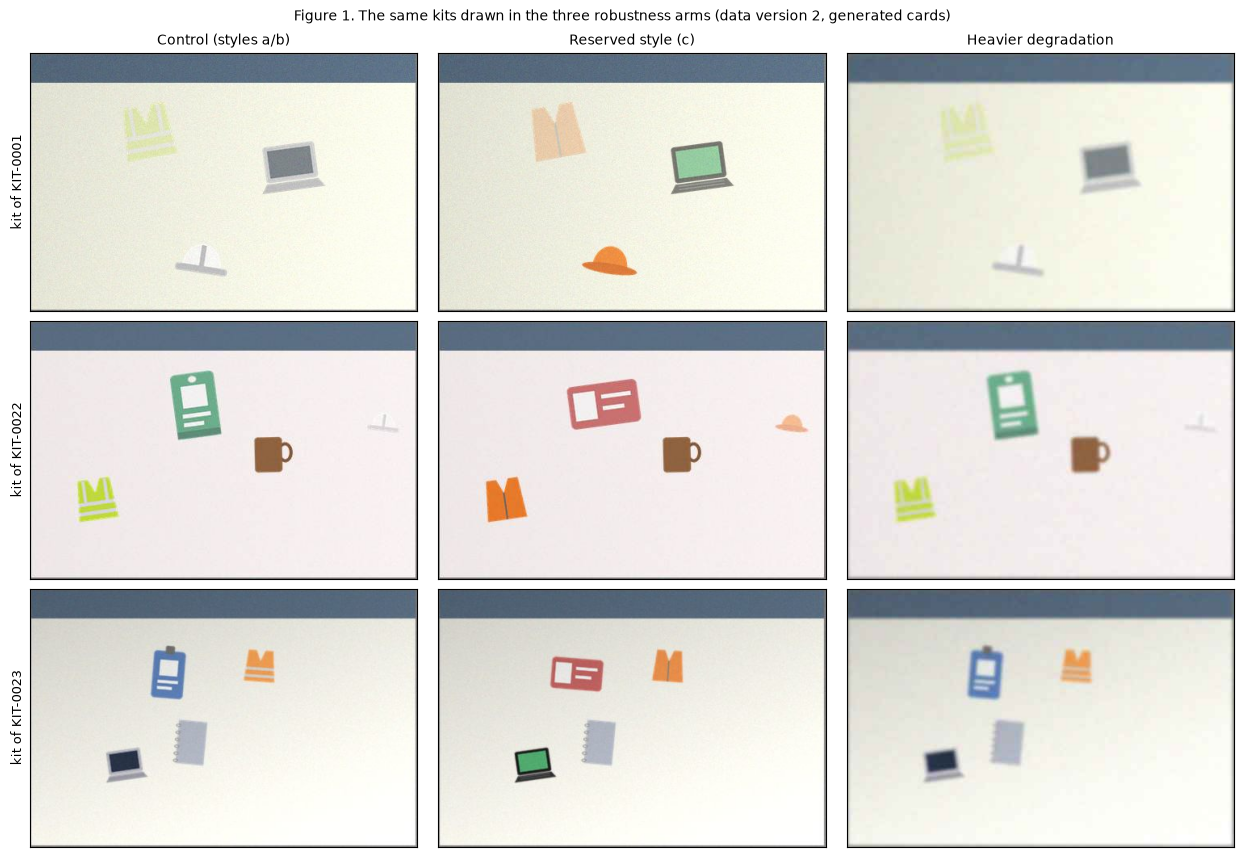

In [4]:
# Figure 1: the same three kits in each arm (the first three validation kits, in card order, with at least three kit items)
example_ids = [c for c in val_cards["card_id"] if (val_objects[(val_objects["card_id"] == c)]["role"] == "kit_item").sum() >= 3][:3]
TITLES = {"control": "Control (styles a/b)", "reserved_style": "Reserved style (c)", "heavier_degradation": "Heavier degradation"}
fig, axes = plt.subplots(len(example_ids), len(ARMS), figsize=(4.2 * len(ARMS), 2.9 * len(example_ids)), squeeze=False)
for i, card_id in enumerate(example_ids):
    for j, arm in enumerate(ARMS):
        axes[i, j].imshow(cv2.cvtColor(images[(arm, card_id)], cv2.COLOR_BGR2RGB))
        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])
        if i == 0:
            axes[i, j].set_title(TITLES[arm], fontsize=10)
        if j == 0:
            axes[i, j].set_ylabel(f"kit of {card_id}", fontsize=9)
fig.suptitle("Figure 1. The same kits drawn in the three robustness arms (data version 2, generated cards)", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "robustness_examples.png", dpi=120, bbox_inches="tight")
plt.show()

**Figure 1 caption.** *What it shows:* three validation kits (the first three in card order with at least three kit items), each drawn in the three arms. Positions, sizes, rotations, paper and background objects are the same across a row. In the reserved style the badge becomes a red horizontal card, the vest orange with a zip, the hard hat orange with a full brim, and the laptop gets a green screen and keyboard lines (the phone, not in these three kits, gets a notch); in the heavier-degradation arm the familiar drawings are blurrier, noisier and more compressed. *Why it matters:* the arms differ only where intended, so differences between their results can be attributed to the change of item designs or to the image-quality condition, on these cards. Because the style-c drawings are often wider (102 of the 238 kit items here), objects are placed using a box that encloses every arm's drawing. *What it can't establish:* how the pipeline performs on these cards, which section C measures, or how real kit items, photographs or scans would look.